# Chapter 12 Lab — Volume, Open Interest and Breadth

**Purpose:** understand what volume and breadth indicators measure, using synthetic data where the true answer is known.

This is a learning notebook, **not** an optimisation exercise and not a backtest. Tests on NIFTY wait for real NSE data and are pre-registered in [Research 003](../research/003-nifty-volume-breadth/HYPOTHESIS.md). Indicator code: [`lib/volume.py`](../lib/volume.py); notes: [`notes/ch12-volume-oi-breadth.md`](../notes/ch12-volume-oi-breadth.md).

## Learning objectives

1. Calculate On-Balance Volume by hand and match Kaufman's Table 12.2.
2. See how erratic volume is compared with price, and why every volume indicator smooths.
3. Measure how much of OBV's picture is simply price.
4. Detect volume spikes with a lagged average, and see why the lag matters.
5. Check what a low-volume filter really removes (the book's 32% claim).
6. Build breadth indicators from a simulated market of 300 stocks, and see breadth fail to confirm a narrow rally.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO))       # so `lib` imports without installing the package
from lib import volume as vol

rng = np.random.default_rng(12)

## 1. On-Balance Volume: Kaufman's Table 12.2

Add the day's volume when the close rises, subtract it when the close falls (p. 537).

In [2]:
table = pd.DataFrame({'close': [310, 315, 318, 316, 314, 320], 'volume': [25, 30, 27, 15, 12, 28]},
                     index=pd.RangeIndex(1, 7, name='day'))
table['OBV'] = vol.obv(table['close'], table['volume'])
table['book OBV'] = [0, 30, 57, 42, 30, 58]
display(table)
assert (table['OBV'] == table['book OBV']).all()
print('Matches Table 12.2.')

,close,volume,OBV,book OBV
day,,,,
1,310,25,0.0,0
2,315,30,30.0,30
3,318,27,57.0,57
4,316,15,42.0,42
5,314,12,30.0,30
6,320,28,58.0,58


Matches Table 12.2.


## 2. Volume is erratic

A synthetic stock: daily returns with 1.2% volatility; volume log-normal with persistence (busy days cluster) and higher on big-move days, as in real markets. Kaufman's Microsoft example (p. 529): daily volume standard deviation ≈ 38% of average volume, against a price standard deviation under 3%.

Volume: daily st. dev. = 43% of average volume
Price:  daily st. dev. of % change = 1.2%


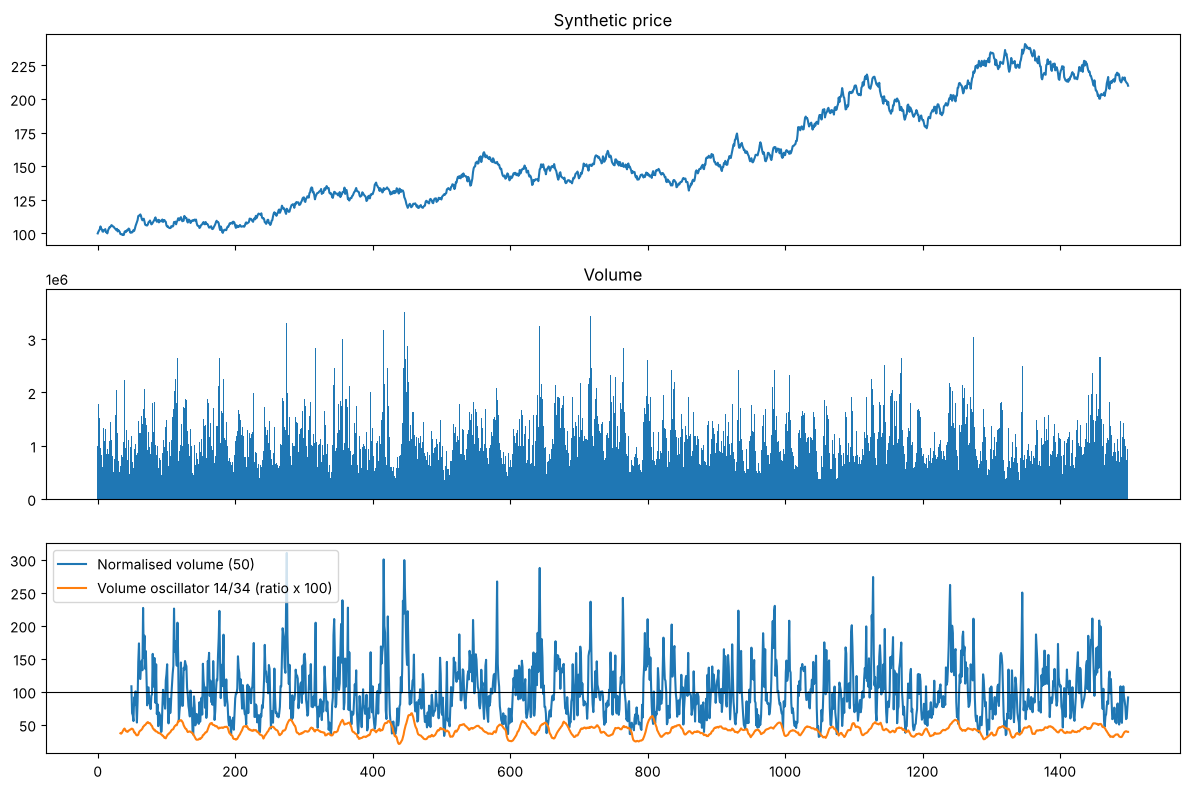

In [3]:
n = 1500
ret = rng.normal(0.0003, 0.012, n)
log_v = np.zeros(n)
for t in range(1, n):                                   # AR(1) in log volume + response to |return|
    log_v[t] = 0.7 * log_v[t - 1] + rng.normal(0, 0.3)
volume = pd.Series(1e6 * np.exp(log_v + 8 * np.abs(ret)), name='volume')
close = pd.Series(100 * np.exp(np.cumsum(ret)), name='close')
high = close * (1 + np.abs(rng.normal(0, 0.006, n)))
low = close * (1 - np.abs(rng.normal(0, 0.006, n)))

print(f'Volume: daily st. dev. = {volume.std() / volume.mean():.0%} of average volume')
print(f'Price:  daily st. dev. of % change = {close.pct_change().std():.1%}')

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(close); axes[0].set_title('Synthetic price')
axes[1].bar(volume.index, volume, width=1.0); axes[1].set_title('Volume')
axes[2].plot(vol.normalized_volume(volume, 50), label='Normalised volume (50)')
axes[2].plot(100 * vol.volume_oscillator(volume, 14, 34, 'ratio'), label='Volume oscillator 14/34 (ratio x 100)')
axes[2].axhline(100, color='black', linewidth=0.8); axes[2].legend()
plt.tight_layout(); plt.show()

## 3. How much of OBV is just price?

OBV uses the **sign of the price change** to decide whether to add or subtract volume. So even when volume carries **no information at all**, OBV inherits the price trend.

Test: two worlds with the same price path.
- **World A (no information):** volume is pure noise, independent of direction.
- **World B (informed):** volume is 50% higher on up days (buyers more active), Kaufman's "volume confirms price".

If OBV looks similar in both worlds, eyeballing an OBV chart cannot tell you whether volume adds anything.

,"corr(20-day OBV change, 20-day price change)","corr(OBV level, price level)"
world,,
A: volume is noise,0.69,0.87
B: volume higher on up days,0.70,0.96


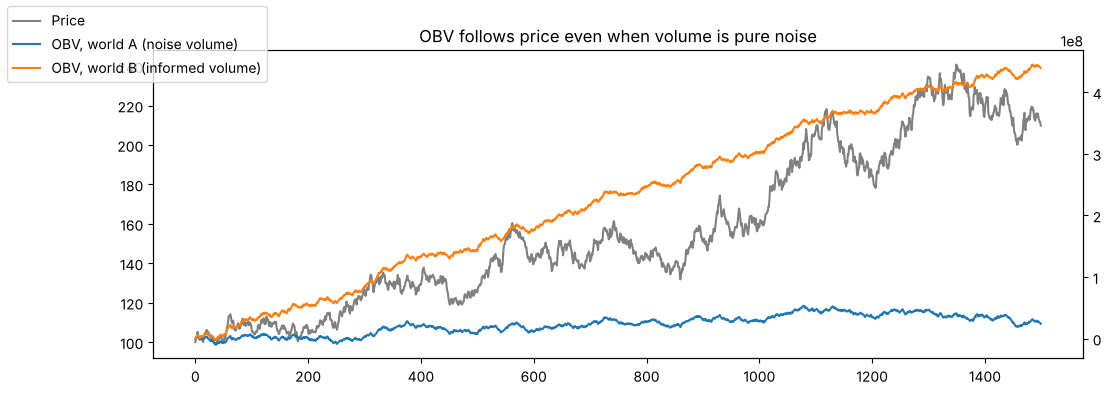

In [4]:
price = close
up = price.diff() > 0
noise_v = pd.Series(1e6 * np.exp(rng.normal(0, 0.4, n)))
informed_v = noise_v * np.where(up, 1.5, 1.0)

obv_a = vol.obv(price, noise_v)
obv_b = vol.obv(price, informed_v)
k = 20
chg_price = price.diff(k)
rows = []
for name, o in [('A: volume is noise', obv_a), ('B: volume higher on up days', obv_b)]:
    rows.append({'world': name,
                 'corr(20-day OBV change, 20-day price change)': o.diff(k).corr(chg_price),
                 'corr(OBV level, price level)': o.corr(price)})
display(pd.DataFrame(rows).set_index('world').round(2))

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(price, color='grey', label='Price')
ax2 = ax1.twinx()
ax2.plot(obv_a, label='OBV, world A (noise volume)')
ax2.plot(obv_b, label='OBV, world B (informed volume)')
ax1.set_title('OBV follows price even when volume is pure noise')
fig.legend(loc='upper left'); plt.show()

**Read the table:** in world A the 20-day OBV change is already strongly correlated with the 20-day price change, though volume knows nothing. World B adds a drift but hardly changes the picture. A volume indicator only earns its place if it **beats the price-only version** in a pre-declared test. That is Research 003's job.

## 4. Volume spikes need a lagged average

Kaufman (p. 555): a spike often builds over 2–3 days. If the average includes those days, it rises with them and the spike can be missed. Lagging the average 5 days is meant to fix that.

Plant 15 three-day build-ups (volume ×1.6, ×2.2, ×3.0) and count how many each rule catches.

In [5]:
base = pd.Series(1e6 * np.exp(rng.normal(0, 0.25, 1200)))
planted = rng.choice(np.arange(60, 1180, 70), size=15, replace=False)
spiky = base.copy()
for p in planted:
    spiky.iloc[p - 2:p + 1] *= [1.6, 2.2, 3.0]

lagged = vol.volume_spike(spiky, n=20, multiple=2.0, lag=5)
unlagged = spiky > 2.0 * spiky.rolling(20).mean()
caught = lambda flags: sum(flags.iloc[p] for p in planted)
print(f'Planted spike peaks caught: lagged average {caught(lagged)}/15, unlagged average {caught(unlagged)}/15')
print(f'Other days flagged:        lagged {int(lagged.sum()) - caught(lagged)}, unlagged {int(unlagged.sum()) - caught(unlagged)}')
assert caught(lagged) >= caught(unlagged)

Planted spike peaks caught: lagged average 14/15, unlagged average 13/15
Other days flagged:        lagged 13, unlagged 10


**Read the counts:** the lag catches build-ups at least as well, but it also flags a few more ordinary busy days, because its threshold ignores the most recent week. The lag, the 20-day window and the ×2 multiple are all parameters; none is free.

## 5. What does a low-volume filter remove?

The book (p. 563): *"a 1 standard deviation filter will remove the lowest 16% of the days; a 2 standard deviation filter removes 32%."* The first is right for a normal distribution. The second is not: a one-sided 2σ cut removes about **2.3%**. (32% is the two-sided ±1σ share.)

Real volume is skewed (log-normal-like), which changes the numbers again.

In [6]:
normal_v = pd.Series(rng.normal(1.5e9, 0.25e9, 100_000))     # the book's NYSE example: mean 1.5bn, sd 0.25bn
lognormal_v = pd.Series(np.exp(rng.normal(0, 0.4, 100_000)))
rows = []
for name, v in [('normal (book example)', normal_v), ('log-normal (skewed, like real volume)', lognormal_v)]:
    for k in (1, 2):
        rows.append({'volume distribution': name, 'filter': f'{k} sd',
                     'share of days removed': (v < v.mean() - k * v.std()).mean()})
out = pd.DataFrame(rows).set_index(['volume distribution', 'filter'])
print((100 * out['share of days removed']).round(1).astype(str) + '%')

volume distribution                    filter
normal (book example)                  1 sd      15.9%
                                       2 sd       2.3%
log-normal (skewed, like real volume)  1 sd      12.6%
                                       2 sd       0.0%
Name: share of days removed, dtype: str


**Read the table:** for normal volume, 1σ removes ~16% and 2σ ~2.3%, not 32%. For skewed volume, mean − 2σ can fall near or below zero and the 2σ filter removes almost nothing. Measure the share on your own data before relying on a σ rule; a percentile cut (e.g. the lowest 10% of days) says what it does.

## 6. Breadth from a simulated market

300 stocks. Each day's return = beta × market factor + own noise. The breadth data are what NSE publishes: number advancing and declining, and the volume traded in each group. The index here is equally weighted, so breadth and index measure the same market.

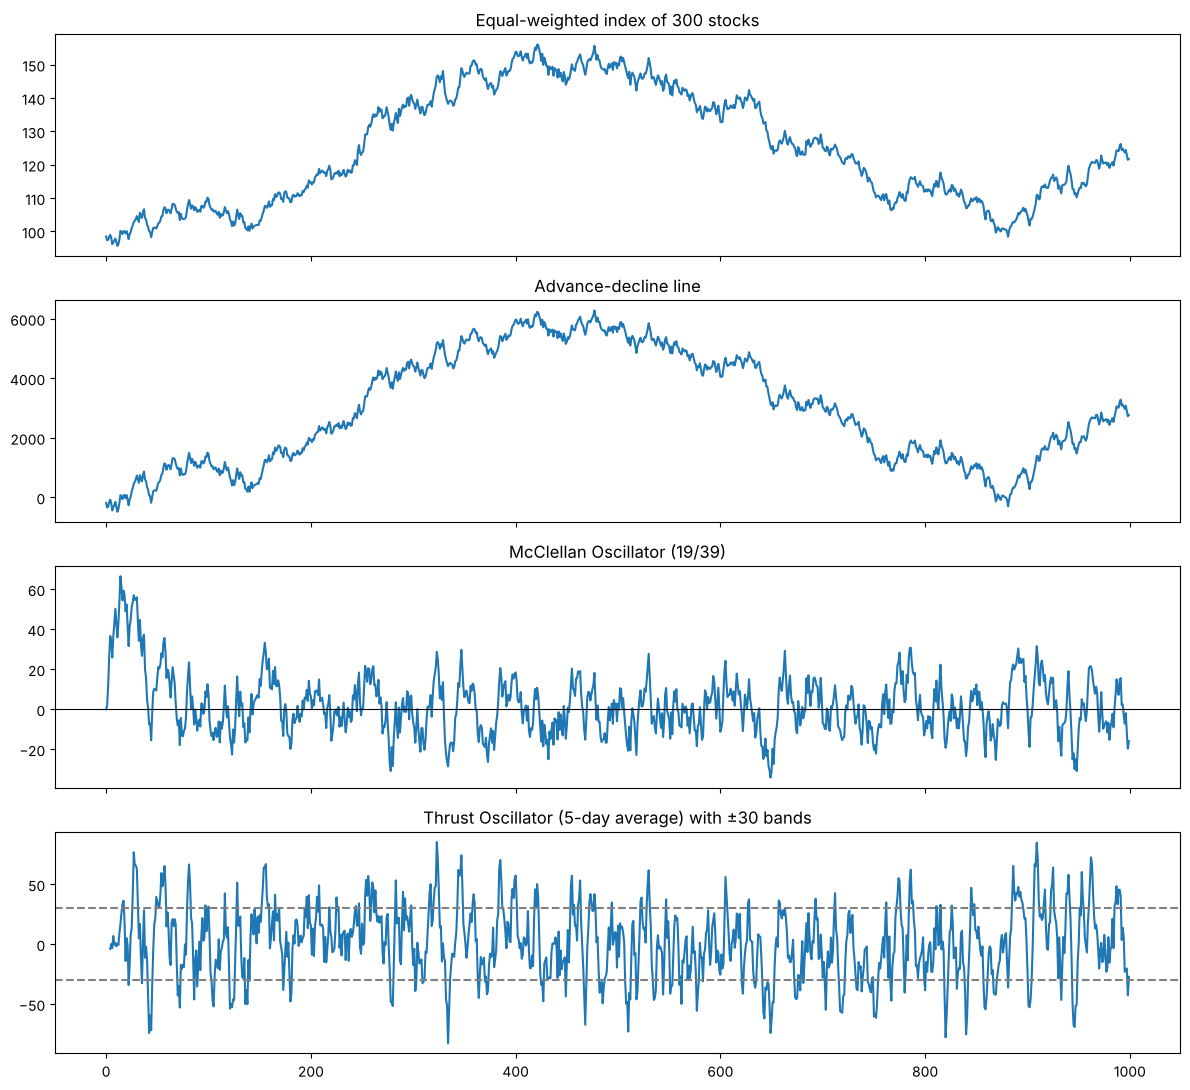

corr(daily A-D, daily index return): 0.99
TRIN: median 1.00; share of days below 1 (volume favours advancers): 53%


In [7]:
n_days, n_stocks = 1000, 300
mkt = rng.normal(0.0003, 0.010, n_days)
beta = rng.uniform(0.6, 1.4, n_stocks)
stock_ret = mkt[:, None] * beta + rng.normal(0, 0.015, (n_days, n_stocks))
stock_vol = np.exp(rng.normal(0, 0.5, (n_days, n_stocks)) + 6 * np.abs(stock_ret))

adv = pd.Series((stock_ret > 0).sum(1), dtype=float)
dec = pd.Series((stock_ret < 0).sum(1), dtype=float)
unch = pd.Series(n_stocks - adv - dec, dtype=float)
adv_v = pd.Series(np.where(stock_ret > 0, stock_vol, 0).sum(1))
dec_v = pd.Series(np.where(stock_ret < 0, stock_vol, 0).sum(1))
index = pd.Series(100 * np.cumprod(1 + stock_ret.mean(1)))

ad = vol.ad_line(adv, dec)
mcc = vol.mcclellan_oscillator(adv, dec)
tr = vol.trin(adv, dec, adv_v, dec_v)
thrust = vol.thrust_oscillator(adv, dec, adv_v, dec_v)

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
axes[0].plot(index); axes[0].set_title('Equal-weighted index of 300 stocks')
axes[1].plot(ad); axes[1].set_title('Advance-decline line')
axes[2].plot(mcc); axes[2].axhline(0, color='black', linewidth=0.8); axes[2].set_title('McClellan Oscillator (19/39)')
axes[3].plot(thrust.rolling(5).mean()); axes[3].axhline(30, ls='--', color='grey'); axes[3].axhline(-30, ls='--', color='grey')
axes[3].set_title('Thrust Oscillator (5-day average) with ±30 bands')
plt.tight_layout(); plt.show()

print(f'corr(daily A-D, daily index return): {(adv - dec).corr(index.pct_change()):.2f}')
print(f'TRIN: median {tr.median():.2f}; share of days below 1 (volume favours advancers): {(tr < 1).mean():.0%}')

### Breadth non-confirmation: a narrow rally

Kaufman (p. 547): *a rising index with more stocks declining should generate concern.* Here a **cap-weighted** index puts 60% weight on 10 large stocks. For 150 days the large stocks rally while the other 290 drift down. The cap-weighted index rises; breadth does not confirm it.

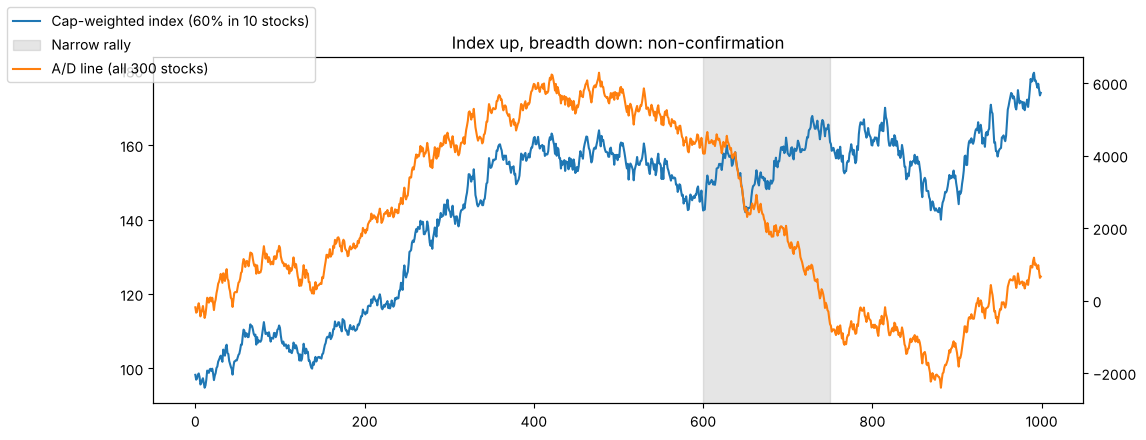

During the narrow rally: index +12.9%, A/D line -4710


In [8]:
r2 = stock_ret.copy()
window = slice(600, 750)
r2[window, :10] += 0.004                       # 10 large caps rally
r2[window, 10:] -= 0.0012                      # the rest drift lower
weights = np.r_[np.full(10, 0.06), np.full(290, 0.40 / 290)]
cap_index = pd.Series(100 * np.cumprod(1 + r2 @ weights))
adv2 = pd.Series((r2 > 0).sum(1), dtype=float)
dec2 = pd.Series((r2 < 0).sum(1), dtype=float)
ad2 = vol.ad_line(adv2, dec2)

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(cap_index, label='Cap-weighted index (60% in 10 stocks)')
ax2 = ax1.twinx()
ax2.plot(ad2, color='tab:orange', label='A/D line (all 300 stocks)')
ax1.axvspan(600, 750, color='grey', alpha=0.2, label='Narrow rally')
fig.legend(loc='upper left'); ax1.set_title('Index up, breadth down: non-confirmation')
plt.show()

idx_chg = cap_index.iloc[750] / cap_index.iloc[600] - 1
ad_chg = ad2.iloc[750] - ad2.iloc[600]
print(f'During the narrow rally: index {idx_chg:+.1%}, A/D line {ad_chg:+.0f}')
assert idx_chg > 0 and ad_chg < 0

**Lessons:** breadth must match the instrument. An equally weighted count of all NSE stocks is not the same market as the cap-weighted NIFTY 50. And non-confirmation is a **warning**, not a timing signal: the lab cannot say when (or whether) the index will follow breadth. Research 003 tests that on NIFTY.

In [9]:
assert (table['OBV'] == table['book OBV']).all()
assert vol.trin(adv, dec, adv_v, dec_v).dropna().gt(0).all()
assert vol.thrust_oscillator(adv, dec, adv_v, dec_v).dropna().between(-100, 100).all()
print('Chapter 12 sanity checks passed.')

Chapter 12 sanity checks passed.


## What is missing before any of this becomes a strategy?

- real NSE volume, open interest and breadth (pipeline ready, not yet run);
- a pre-declared test that the volume or breadth version **beats the price-only version** (Research 003);
- futures roll and lot-size handling for long histories (use value or OI × price);
- costs, execution timing, exits and position sizing.

## Reflection

1. Why does Kaufman insist on total futures volume and open interest?
2. Why did OBV track price in world A, where volume was pure noise?
3. Why does the volume-spike rule lag its average by five days?
4. What share of days does a 2σ low-volume filter remove, and why is the book's 32% wrong?
5. Why can a cap-weighted index rise while the A/D line falls, and what should you do about it?